# Sentiment modelling

We describe sentiment by guest experience aspect, and compare one simple classifier with a BERT-family model, RoBERTa-base.



## 1. Load the prepared data

The cleaning notebook saves two inputs: all reviews for business analysis, and a deduplicated corpus for model training. We keep original review text for RoBERTa and cleaned text for TF-IDF.

### Libraries and folders

In [1]:
%pip install mlflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install bertopic sentence-transformers umap-learn hdbscan

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys, re, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Paths
PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "data" / "raw").is_dir() and (p / "src").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the project root or its notebook folder before running.")
RAW_DIR   = PROJECT_ROOT / "data" / "raw"
PROC_DIR  = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MLRUNS_DIR = PROJECT_ROOT / "mlruns"
for d in (RAW_DIR, PROC_DIR, MODEL_DIR, MLRUNS_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from text_preprocessing import (clean_text, preprocess_corpus, split_sentences,
                                strip_connectors, normalise_unicode, LEVELS, STOP_WORDS)



### Settings 

In [4]:
SEED = 42
SENT_ORDER = ['negative', 'neutral', 'positive']
SENT_COLORS = {'negative': '#C8553D', 'neutral': '#B9B9B9', 'positive': '#2A9D8F'}
RUN_BERT = 'auto'             # 'auto': reuse verified results; True: retrain; False: skip training
TRAINING_MODE = 'quick'        # 'quick' for learning; 'full' for the original training budget
TOPIC_BACKEND = 'transformer'  # 'transformer': MiniLM embeddings; 'tfidf': explicit lightweight alternative
BERT_MODEL_NAME = 'roberta-base'
BERT_LABEL = 'RoBERTa-base'
BERT_TRAIN_LIMIT = 1500 if TRAINING_MODE == 'quick' else 6000
EPOCHS = 1 if TRAINING_MODE == 'quick' else 3
ML_N_JOBS = 1
WRITE_OUTPUTS_TO_DB = False


### Tracking and shared imports

In [5]:
np.random.seed(SEED)
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(exist_ok=True)
from IPython.display import display, Markdown
import hashlib, joblib, mlflow
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
mlflow.set_tracking_uri(f"sqlite:///{(MLRUNS_DIR / 'mlflow.db').as_posix()}")
NOTEBOOK_START = pd.Timestamp.now(tz='UTC')
def use_experiment(name):
    if mlflow.get_experiment_by_name(name) is None:
        mlflow.create_experiment(name, artifact_location=(MLRUNS_DIR / 'artifacts' / name).resolve().as_uri())
    mlflow.set_experiment(name)
print('Project folder:', PROJECT_ROOT)
print('Training mode:', TRAINING_MODE, '| RUN_BERT:', RUN_BERT, '| topic backend:', TOPIC_BACKEND)



Project folder: D:\Amdari\Project_montra
Training mode: quick | RUN_BERT: auto | topic backend: transformer


### Read the clean CSV files

In [6]:
required = ['reviews_clean.csv', 'nlp_corpus.csv']
missing = [f for f in required if not (PROC_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Run cleaning_eda.ipynb first. Missing: {missing}")
reviews_clean = pd.read_csv(PROC_DIR / 'reviews_clean.csv')
nlp_corpus = pd.read_csv(PROC_DIR / 'nlp_corpus.csv')
hotels_raw = pd.read_csv(RAW_DIR / 'hotels.csv')
for col in ['review_date', 'check_in_date', 'check_out_date']:
    if col in reviews_clean:
        reviews_clean[col] = pd.to_datetime(reviews_clean[col])
assert reviews_clean.review_id.is_unique
assert nlp_corpus.review_text.is_unique

print('All reviews:', len(reviews_clean), '| unique modelling reviews:', len(nlp_corpus))
display(nlp_corpus[['review_text', 'sentiment_label']].head(3))


All reviews: 35000 | unique modelling reviews: 34460


,review_text,sentiment_label
0,The overall price was fair for what we paid. M...,neutral
1,The room was nothing out of the ordinary for w...,positive
2,"Unfortunately, the pool was outdated — it clea...",negative


## 2. Create the training validation and test sets

Training teaches the model; validation compares models. The 70/15/15 stratified split keeps the class proportions similar. Fixed random seeds reproduce the split.

In [7]:
corpus = nlp_corpus.reset_index(drop=True)
train_df, remaining = train_test_split(corpus, test_size=0.30, stratify=corpus.sentiment_label, random_state=SEED)
val_df, test_df = train_test_split(remaining, test_size=0.50, stratify=remaining.sentiment_label, random_state=SEED)
split_ids = {name: frame.review_id.tolist() for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]}
split_table = pd.concat([train_df.assign(split='train'), val_df.assign(split='validation'), test_df.assign(split='test')])
split_table[['review_id', 'split']].to_csv(PROC_DIR / 'model_splits.csv', index=False)
assert not (set(train_df.review_text) & set(test_df.review_text))
data_signature = hashlib.sha256(pd.util.hash_pandas_object(
    corpus[['review_id', 'review_text', 'sentiment_label']], index=False).values.tobytes()).hexdigest()
display(pd.crosstab(split_table['split'], split_table['sentiment_label']).reindex(columns=SENT_ORDER))


sentiment_label,negative,neutral,positive
split,,,
test,1459,1960,1750
train,6808,9146,8168
validation,1459,1960,1750


## 3. Train one simple sentiment baseline

TF-IDF measures how informative words are within reviews. Logistic Regression learns which weighted words help distinguish negative, neutral and positive reviews. This is a fast benchmark for RoBERTa.

In [8]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(sublinear_tf=True, min_df=2)),
    ('clf', LogisticRegression(C=4, max_iter=3000, class_weight='balanced', random_state=SEED))
])
t0 = time.time()
baseline.fit(train_df.text_clean, train_df.sentiment_label)
val_pred = baseline.predict(val_df.text_clean)
def eval_metrics(y_true, y_pred, prefix=''):
    result = {'accuracy': accuracy_score(y_true, y_pred),
              'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
              'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
              'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0)}
    result.update({f'f1_{label}': score for label, score in zip(
        SENT_ORDER, f1_score(y_true, y_pred, labels=SENT_ORDER, average=None, zero_division=0))})
    return {prefix + key: float(value) for key, value in result.items()}
baseline_pipes = {'Logistic Regression': baseline}
baseline_results = pd.DataFrame([{'model': 'Logistic Regression',
    **eval_metrics(val_df.sentiment_label, val_pred, 'val_'), 'train_seconds': time.time() - t0}]).set_index('model')
use_experiment('montra-sentiment')
with mlflow.start_run(run_name='simplified_logistic_baseline'):
    mlflow.set_tag('stage', 'baseline')
    mlflow.log_params({'model': 'Logistic Regression', 'features': 'word_1gram', 'preprocessing': 'standard'})
    mlflow.log_metrics(baseline_results.iloc[0].to_dict())
display(baseline_results.round(4))


,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_f1_negative,val_f1_neutral,val_f1_positive,train_seconds
model,,,,,,,,
Logistic Regression,0.9389,0.9437,0.9379,0.9403,0.9473,0.9217,0.952,1.0935


**How to read the result:** macro-F1 gives each sentiment class equal weight. Check neutral F1 as well as overall accuracy. A higher validation score is better, but the held-out test set must remain separate from model tuning.

## 4. Prepare sentences for topic discovery

A review can mention breakfast, staff and cleanliness together. Splitting reviews into sentences makes the topics more specific. We embed unique aspect phrases once, then map them back to every review. The vocabulary is a transparent domain guide; this makes the method a hybrid of discovered clusters and business rules.

In [9]:
rows = [(rid, i, sentence, strip_connectors(sentence))
        for rid, text in zip(reviews_clean.review_id, reviews_clean.review_text)
        for i, sentence in enumerate(split_sentences(text))]
sentences = pd.DataFrame(rows, columns=['review_id', 'sent_idx', 'sentence_raw', 'sentence'])
sentences['key'] = sentences.sentence.str.lower()
uniq = sentences.drop_duplicates('key')[['key', 'sentence']].copy()
uniq['clean'] = uniq.sentence.map(clean_text)
ASPECT_LEXICON = {
    'Staff & Service': {
        'attentive', 'bartender', 'complaints', 'concierge', 'courteous', 'dismissive', 'friendly',
        'helpful', 'indifferent', 'luggage', 'manager', 'names', 'night', 'overworked',
        'polite', 'professional', 'receptionist', 'request', 'respond', 'rude', 'service',
        'staff', 'team', 'unhelpful', 'welcoming',
    },
    'Cleanliness': {
        'clean', 'dirty', 'dusty', 'filthy', 'freshly', 'gleaming', 'grimy',
        'grubby', 'housekeeping', 'hygiene', 'immaculate', 'kept', 'musty', 'neglected',
        'pristine', 'scrubbed', 'sparkling', 'spick', 'spotless', 'stained', 'tidy',
        'unhygienic', 'unkempt', 'wiped',
    },
    'Rooms & Common Areas': {
        'bathroom', 'bed', 'bedding', 'carpet', 'comfortable', 'commonareas', 'cor',
        'decor', 'furniture', 'noise', 'quiet', 'room', 'shower', 'suite',
    },
    'Food & Dining': {
        'breakfast', 'buffet', 'cafe', 'dining', 'dinner', 'dishes', 'edible',
        'fare', 'food', 'inhouse', 'menu', 'pastries', 'restaurant', 'roomservice',
        'variety',
    },
    'Location & Transport': {
        'car', 'central', 'city', 'convenient', 'exploring', 'links', 'location',
        'nearby', 'neighborhood', 'parking', 'placed', 'public', 'reach', 'situated',
        'surrounding', 'transport', 'walk',
    },
    'Pricing & Value': {
        'affordable', 'amenities', 'charge', 'cost', 'deal', 'expensive', 'money',
        'overpriced', 'price', 'pricing', 'rate', 'value',
    },
    'Facilities': {
        'business', 'center', 'connection', 'equipment', 'equipped', 'facilities', 'fi',
        'fitness', 'gym', 'lounge', 'pool', 'spa', 'wi', 'wifi',
    },
    'Check-in & Arrival': {
        'arrival', 'check', 'checked', 'checkin', 'desk', 'front', 'process',
        'queue', 'ready', 'waited',
    },
}
ASPECT_GROUP = {'Cleanliness': 'Cleanliness & Room Condition', 'Rooms & Common Areas': 'Cleanliness & Room Condition'}
def business_aspect(name):
    return ASPECT_GROUP.get(name, name)
# Keep nouns for clustering so topics are less dominated by praise/complaint words.
TOPIC_NOUNS = set('staff team service manager receptionist concierge luggage room suite bed bedding carpet bathroom shower furniture breakfast buffet restaurant dining cafe food pastries menu dinner location neighborhood transport city parking price cost rate pricing value money pool gym fitness spa lounge facilities wifi equipment check arrival desk queue process'.split())
uniq['topic_text'] = uniq.clean.map(lambda text: ' '.join(word for word in text.split() if word in TOPIC_NOUNS))
topic_docs = uniq.loc[uniq.topic_text.str.strip().ne(''), 'topic_text'].drop_duplicates().tolist()
print(f'{len(sentences):,} sentences; {len(uniq):,} unique sentences; {len(topic_docs):,} unique aspect phrases')
display(uniq[['sentence', 'topic_text']].head(8))


85,829 sentences; 6,764 unique sentences; 131 unique aspect phrases


,sentence,topic_text
0,The overall price was fair for what we paid.,price
1,"Might consider it again, might not.",
2,The room was nothing out of the ordinary for w...,room
3,The overall price exceeded our expectations -...,price price
4,the pool was outdated - it clearly needed so...,pool
5,Wouldn't recommend it to others.,
6,We were disappointed that the neighborhood was...,neighborhood
7,the room turned out to be grimy.,room


## 5. Fit one BERTopic model

MiniLM converts phrases into vectors representing their meaning. BERTopic groups similar vectors and describes each group with representative words. We use one fixed configuration here. The optional TF-IDF backend is faster and avoids a transformer download, but changes the method and potentially the findings.

In [10]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
if len(topic_docs) < 10:
    raise ValueError('Too few unique aspect phrases for this configuration.')
cache_key = hashlib.sha256((TOPIC_BACKEND + '\n' + '\n'.join(topic_docs)).encode()).hexdigest()[:16]
embedding_path = PROC_DIR / f'simplified_topic_embeddings_{cache_key}.npz'
if embedding_path.exists():
    embeddings = np.load(embedding_path)['embeddings']
    print('Loaded matching topic embeddings from disk.')
elif TOPIC_BACKEND == 'transformer':
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    embeddings = encoder.encode(topic_docs, normalize_embeddings=True, show_progress_bar=True)
    np.savez_compressed(embedding_path, embeddings=embeddings)
elif TOPIC_BACKEND == 'tfidf':
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import normalize
    matrix = TfidfVectorizer().fit_transform(topic_docs)
    embeddings = normalize(TruncatedSVD(n_components=min(50, matrix.shape[0]-1, matrix.shape[1]-1), random_state=SEED).fit_transform(matrix))
    np.savez_compressed(embedding_path, embeddings=embeddings)
else:
    raise ValueError("TOPIC_BACKEND must be 'transformer' or 'tfidf'.")
topic_model = BERTopic(
    umap_model=UMAP(n_neighbors=10, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=5, min_samples=2, prediction_data=True),
    vectorizer_model=CountVectorizer(ngram_range=(1, 2), stop_words='english'), verbose=False)
topics, _ = topic_model.fit_transform(topic_docs, embeddings)
phrase_to_topic = dict(zip(topic_docs, topics))
uniq['topic'] = uniq.topic_text.map(phrase_to_topic)
topic_table = topic_model.get_topic_info()
display(topic_table[['Topic', 'Count', 'Name']].head(20))
use_experiment('montra-topic-modelling')
with mlflow.start_run(run_name='simplified_single_configuration'):
    mlflow.log_params({'embedding': TOPIC_BACKEND, 'min_cluster_size': 5, 'unit': 'unique aspect phrase'})
    mlflow.log_metrics({'n_topics': float(sum(topic_table.Topic != -1)), 'outlier_phrase_share': float(np.mean(np.asarray(topics) == -1))})


Loaded matching topic embeddings from disk.


,Topic,Count,Name
0,-1,6,-1_room service_room_suite check_team suite
1,0,22,0_price_price price_cost_pricing
2,1,16,1_staff_lounge_fitness facilities_lounge staff
3,2,15,2_bathroom_carpet_bedding_bathroom bathroom
4,3,15,3_rate_cost rate_rate rate_cost
5,4,10,4_pastries_pastries breakfast_restaurant_dining
6,5,8,5_transport_neighborhood_location_city
7,6,8,6_luggage_concierge_luggage concierge_team lug...
8,7,8,7_queue_dining queue_queue room_queue queue
9,8,6,8_check process_process_check_process room


**How to read the topics:** Topic -1 contains phrases that do not fit a cluster. Count is the number of unique aspect phrases in that cluster, not the number of reviews. Inspect representative words and example sentences before naming a topic.

## 6. Translate topics into business aspects

We name clusters using the business vocabulary. If a sentence does not contain words supporting its cluster’s aspect, a sentence-level vocabulary check is used. This rule is visible and auditable; aspect names are not produced by BERTopic alone.

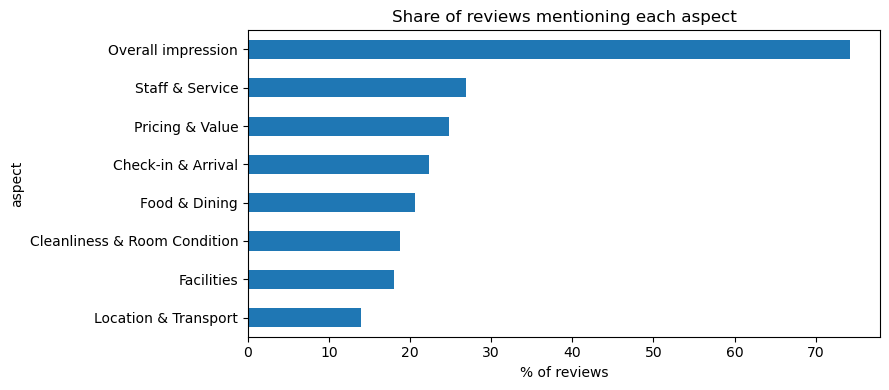

,sentence,aspect,assigned_by
24653,we were disappointed that the bathroom area wa...,Cleanliness & Room Condition,BERTopic
54540,"The overall price was reasonable enough, nothi...",Pricing & Value,BERTopic
68128,An okay option if nothing else is available.,Overall impression,no aspect words
31393,getting checked in stood out as well organized...,Staff & Service,keyword fallback
7225,We had a wonderful time during our stay in Liv...,Overall impression,no aspect words
59319,The night staff left a lot to be desired; we h...,Staff & Service,keyword fallback
43821,I was genuinely impressed that the rate we pai...,Pricing & Value,BERTopic
63808,"The check-in process was fine, nothing more an...",Check-in & Arrival,BERTopic
69174,"the front desk team was adequate, nothing more...",Check-in & Arrival,keyword fallback
55632,"the night staff was remarkably helpful, and th...",Staff & Service,keyword fallback


In [11]:
def map_aspect(word_weights):
    scores = {aspect: sum(weight for word, weight in word_weights for token in word.split() if token in lexicon)
              for aspect, lexicon in ASPECT_LEXICON.items()}
    total = sum(scores.values())
    best = max(scores, key=scores.get)
    return (best, scores[best] / total) if total else ('Other', 0.0)
def choose_aspect(row):
    if not row.topic_text.strip():
        return 'Overall impression', 'no aspect words'
    topic_aspect = map_aspect(topic_model.get_topic(int(row.topic)))[0] if pd.notna(row.topic) and row.topic != -1 else 'Other'
    words = set(row.clean.split())
    if topic_aspect != 'Other' and words & ASPECT_LEXICON[topic_aspect]:
        return business_aspect(topic_aspect), 'BERTopic'
    hits = {name: len(words & lexicon) for name, lexicon in ASPECT_LEXICON.items()}
    best = max(hits, key=hits.get)
    return (business_aspect(best), 'keyword fallback') if hits[best] else ('Other', 'unassigned')
uniq[['aspect', 'assigned_by']] = uniq.apply(choose_aspect, axis=1, result_type='expand')
ASPECTS = [business_aspect(name) for name in ASPECT_LEXICON] + ['Overall impression']
ASPECTS = list(dict.fromkeys(name for name in ASPECTS if name in set(uniq.aspect)))
sentences = sentences.merge(uniq[['key', 'topic', 'aspect', 'assigned_by']], on='key', how='left', validate='many_to_one')
mention = sentences.groupby('aspect').review_id.nunique().sort_values()
(100 * mention / len(reviews_clean)).plot.barh(figsize=(9, 4), title='Share of reviews mentioning each aspect')
plt.xlabel('% of reviews'); plt.tight_layout(); plt.show()
display(sentences[['sentence', 'aspect', 'assigned_by']].sample(10, random_state=SEED))


## 7. Estimate sentiment for each aspect

For a fast first analysis, the Logistic Regression baseline scores each unique sentence. It was trained on review labels, so sentence scores are estimates and need manual checking. These are exploratory portfolio summaries, not independently validated aspect-level predictions.

sent_pred,negative,neutral,positive,mentions,net_sentiment
aspect,,,,,
Staff & Service,0.239,0.471,0.289,9669,4.975
Cleanliness & Room Condition,0.218,0.470,0.312,6594,9.402
Food & Dining,0.194,0.537,0.269,7265,7.515
Location & Transport,0.230,0.477,0.294,4879,6.395
Pricing & Value,0.233,0.512,0.254,8723,2.109
Facilities,0.225,0.501,0.273,6322,4.809
Check-in & Arrival,0.258,0.496,0.246,7943,-1.221
Overall impression,0.267,0.433,0.300,34434,3.360


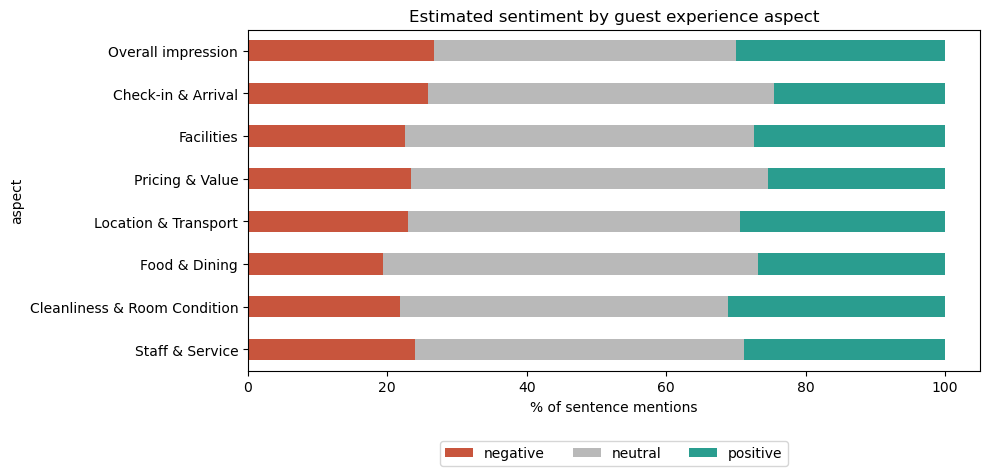

In [12]:
uniq['sent_pred'] = baseline.predict(uniq.clean)
uniq['sent_conf'] = baseline.predict_proba(uniq.clean).max(axis=1)
sentences = sentences.merge(uniq[['key', 'sent_pred', 'sent_conf']], on='key', how='left', validate='many_to_one')
asp = sentences[sentences.aspect != 'Other']
aspect_sent = pd.crosstab(asp.aspect, asp.sent_pred, normalize='index').reindex(columns=SENT_ORDER, fill_value=0).reindex(ASPECTS)
aspect_sent['mentions'] = asp.groupby('aspect').size()
aspect_sent['net_sentiment'] = 100 * (aspect_sent.positive - aspect_sent.negative)
display(aspect_sent.round(3))
(aspect_sent[SENT_ORDER] * 100).plot.barh(stacked=True, color=[SENT_COLORS[s] for s in SENT_ORDER], figsize=(10, 5))
plt.xlabel('% of sentence mentions'); plt.title('Estimated sentiment by guest experience aspect')
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=3); plt.tight_layout(); plt.show()


**Interpretation:** prioritise aspects that combine many mentions with a high negative share. Net sentiment is positive percentage minus negative percentage; it is measured in percentage points. Portfolio averages can hide differences between hotels.

## 8. Examine rating associations and hotel differences

The next two outputs retain the original rating-association and hotel comparison analyses. Regression coefficients describe association within this dataset; they do not prove that changing an aspect causes a rating increase.

Aspect sentiment alone explains R² = 0.738 of the variation in rating_score


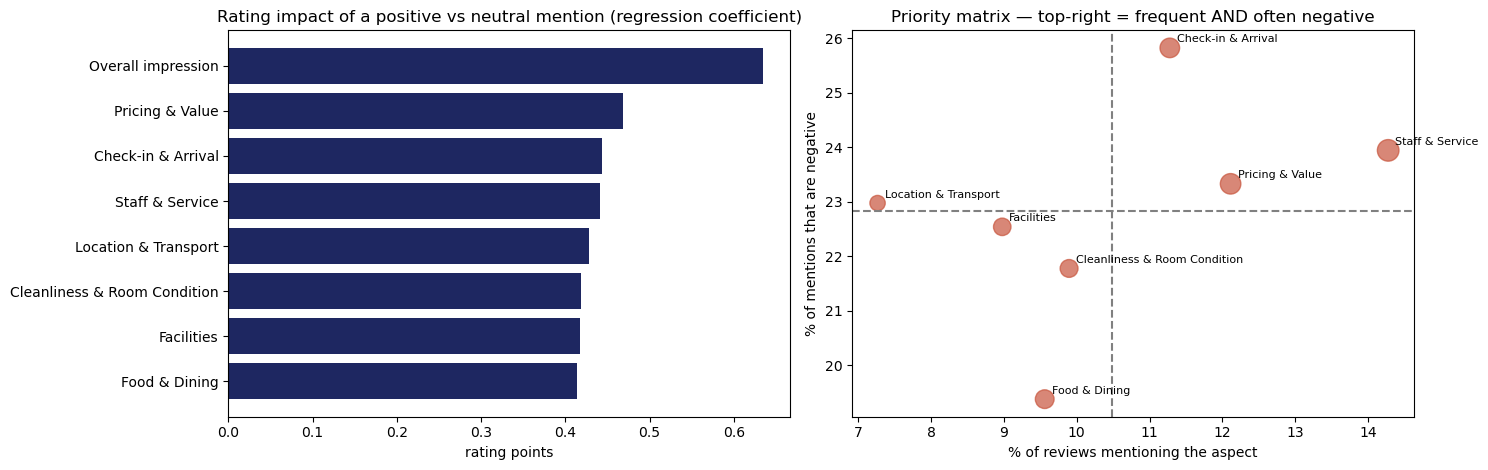

,rating impact (±1 mention),avg rating | aspect negative,avg rating | aspect positive,mention share
aspect,,,,
Overall impression,+0.635,1.89,4.07,43.4%
Pricing & Value,+0.468,1.87,4.07,12.1%
Check-in & Arrival,+0.444,1.89,4.08,11.3%
Staff & Service,+0.441,1.88,4.05,14.3%
Location & Transport,+0.428,1.90,4.07,7.3%
Cleanliness & Room Condition,+0.419,1.87,4.06,9.9%
Facilities,+0.417,1.88,4.07,9.0%
Food & Dining,+0.414,1.89,4.07,9.6%


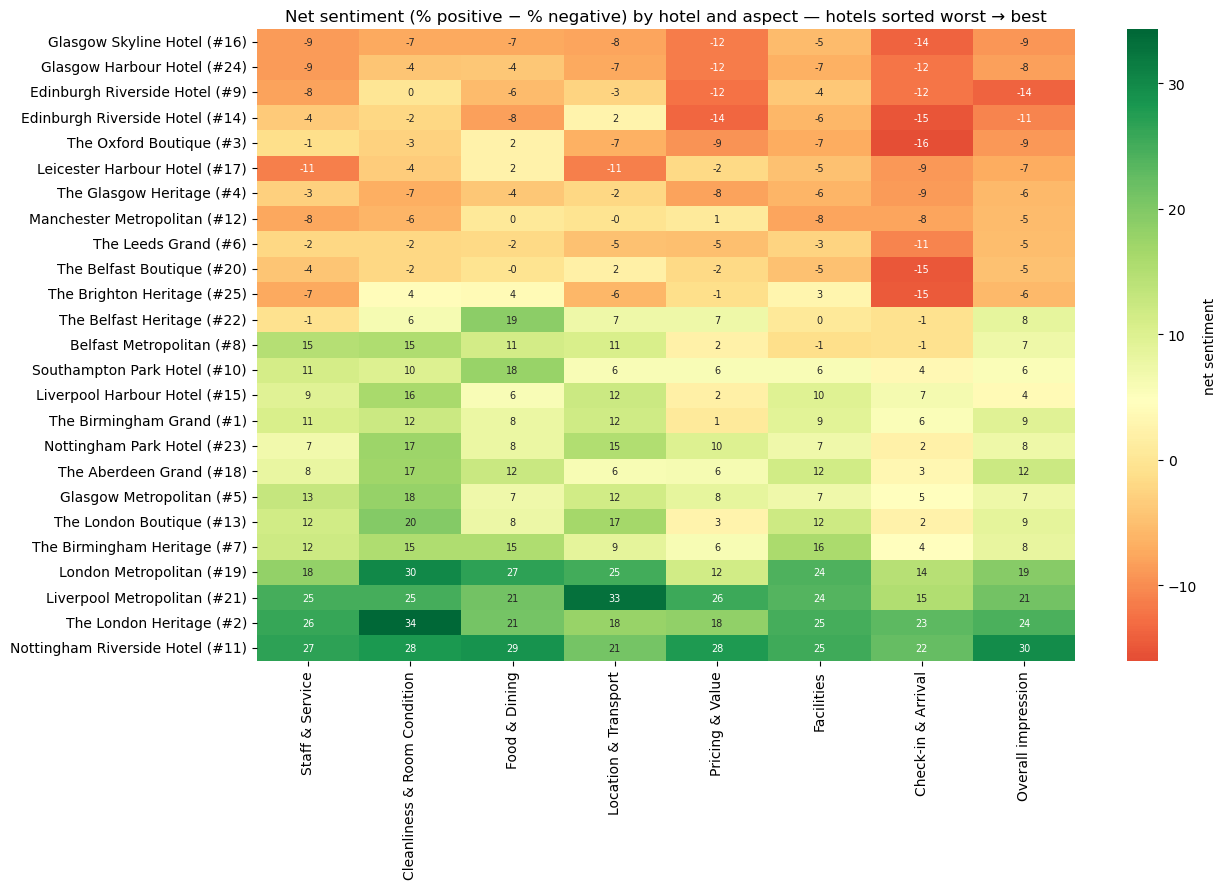

In [13]:
from sklearn.linear_model import LinearRegression
# +1 positive mention, -1 negative mention, 0 neutral/absent — per review and aspect
score_map = {"positive": 1, "neutral": 0, "negative": -1}
asp_matrix = (asp.assign(v=asp["sent_pred"].map(score_map))
              .pivot_table(index="review_id", columns="aspect", values="v", aggfunc="mean")
              .reindex(reviews_clean.review_id).fillna(0))
y_rating = reviews_clean.set_index("review_id").loc[asp_matrix.index, "rating_score"]
reg = LinearRegression().fit(asp_matrix, y_rating)
drivers = pd.DataFrame({"rating impact (±1 mention)": reg.coef_}, index=asp_matrix.columns)
drivers["avg rating | aspect negative"] = [y_rating[asp_matrix[a] < 0].mean() for a in drivers.index]
drivers["avg rating | aspect positive"] = [y_rating[asp_matrix[a] > 0].mean() for a in drivers.index]
drivers["mention share"] = (asp_matrix != 0).mean()
drivers = drivers.sort_values("rating impact (±1 mention)", ascending=False)
print(f"Aspect sentiment alone explains R² = {reg.score(asp_matrix, y_rating):.3f} of the variation in rating_score")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].barh(drivers.index[::-1], drivers.iloc[::-1, 0], color="#1E2761")
ax[0].set_title("Rating impact of a positive vs neutral mention (regression coefficient)"); ax[0].set_xlabel("rating points")
pm = aspect_sent.join(drivers["mention share"]).drop(index="Overall impression", errors="ignore")
ax[1].scatter(pm["mention share"] * 100, pm["negative"] * 100, s=pm["mentions"] / 40, color="#C8553D", alpha=0.7)
for a_, r_ in pm.iterrows():
    ax[1].annotate(a_, (r_["mention share"] * 100, r_["negative"] * 100), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax[1].axhline(pm["negative"].mean() * 100, ls="--", color="grey"); ax[1].axvline(pm["mention share"].mean() * 100, ls="--", color="grey")
ax[1].set_xlabel("% of reviews mentioning the aspect"); ax[1].set_ylabel("% of mentions that are negative")
ax[1].set_title("Priority matrix — top-right = frequent AND often negative")
plt.tight_layout(); plt.show()
display(drivers.style.format({"rating impact (±1 mention)": "{:+.3f}", "avg rating | aspect negative": "{:.2f}",
                              "avg rating | aspect positive": "{:.2f}", "mention share": "{:.1%}"}))

hs = asp.merge(reviews_clean[["review_id", "hotel_label"]], on="review_id")
heat = (hs.groupby(["hotel_label", "aspect"])["sent_pred"]
        .apply(lambda s: ((s == "positive").mean() - (s == "negative").mean()) * 100).unstack())[ASPECTS]
heat = heat.loc[heat.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(heat, cmap="RdYlGn", center=heat.values.mean(), annot=True, fmt=".0f", annot_kws={"size": 7}, cbar_kws={"label": "net sentiment"}, ax=ax)
ax.set_title("Net sentiment (% positive − % negative) by hotel and aspect — hotels sorted worst → best"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
dev = heat.drop(columns=["Overall impression"]).sub(heat.drop(columns=["Overall impression"]).mean(axis=0), axis=1)
worst = dev.stack().sort_values().head(10).rename("net sentiment vs portfolio average").to_frame()
display(worst.style.format("{:+.1f}"))

## 9. Decide whether to reuse or train RoBERTa

RoBERTa reads word sequences in context. Saved prediction arrays can be reused only when the data and ordered split IDs match. Cached predictions support the reference comparison; they do not contain trainable model weights.

In [14]:
BERT_SAVE_DIR = MODEL_DIR / 'bert_sentiment'
BERT_RESULTS_PATH = PROC_DIR / 'bert_results.json'
IDENTITY_PATH = PROC_DIR / 'bert_cache_identity.json'
LABEL2ID = {label: i for i, label in enumerate(SENT_ORDER)}
identity = {'data_signature': data_signature, 'split_ids': split_ids}
bert_runs, BERT_FROM_CACHE = [], False
if RUN_BERT != True and BERT_RESULTS_PATH.exists():
    if IDENTITY_PATH.exists():
        matches = json.loads(IDENTITY_PATH.read_text()) == identity
    else:
        if not all((PROC_DIR / f).exists() for f in ['reference_nlp_corpus.csv', 'reference_model_splits.csv']):
            raise FileNotFoundError('Cannot verify cached predictions. Copy the reference CSVs from this update into data/processed, or set RUN_BERT=True to retrain.')
        reference_corpus = pd.read_csv(PROC_DIR / 'reference_nlp_corpus.csv')
        reference_splits = pd.read_csv(PROC_DIR / 'reference_model_splits.csv')
        ref_signature = hashlib.sha256(pd.util.hash_pandas_object(
            reference_corpus[['review_id', 'review_text', 'sentiment_label']], index=False).values.tobytes()).hexdigest()
        matches = ref_signature == data_signature and reference_splits.equals(pd.read_csv(PROC_DIR / 'model_splits.csv'))
    if not matches:
        raise ValueError('Cached predictions belong to different data/splits. Set RUN_BERT=True to train again.')
    bert_runs = json.loads(BERT_RESULTS_PATH.read_text())
    for run in bert_runs:
        assert len(run['val_pred']) == len(val_df) and len(run['test_pred']) == len(test_df)
    BERT_FROM_CACHE = True
    print('Reusing verified reference results; no new RoBERTa training.')
    print('The reference runs have their own training settings, independent of TRAINING_MODE.')
TRAIN_NOW = not BERT_FROM_CACHE and RUN_BERT != False
if TRAIN_NOW:
    print(f'Training next: up to {BERT_TRAIN_LIMIT:,} reviews; {EPOCHS} epoch(s).')


Reusing verified reference results; no new RoBERTa training.
The reference runs have their own training settings, independent of TRAINING_MODE.


## 10. Tokenise reviews for RoBERTa

Tokenisation converts text into the subword IDs expected by RoBERTa. We preserve the original wording, truncate to 64 tokens, and keep sentiment labels as integers. The quick sample is drawn only from the training split.

In [15]:
if TRAIN_NOW:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, set_seed
    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
    training_sample = train_df
    if len(train_df) > BERT_TRAIN_LIMIT:
        training_sample, _ = train_test_split(train_df, train_size=BERT_TRAIN_LIMIT,
            stratify=train_df.sentiment_label, random_state=SEED)
    class ReviewDataset(torch.utils.data.Dataset):
        def __init__(self, frame):
            self.tokens = tokenizer(frame.review_text.map(normalise_unicode).tolist(), truncation=True, max_length=64)
            self.labels = frame.sentiment_label.map(LABEL2ID).tolist()
        def __len__(self):
            return len(self.labels)
        def __getitem__(self, i):
            return {**{key: value[i] for key, value in self.tokens.items()}, 'labels': self.labels[i]}
    training_data = ReviewDataset(training_sample)
    validation_data = ReviewDataset(val_df)
    print('Training rows:', len(training_data), '| validation rows:', len(validation_data))
else:
    print('Tokenisation skipped because we are reusing results or training is disabled.')


Tokenisation skipped because we are reusing results or training is disabled.


## 11. Fine tune and save RoBERTa

An epoch is one pass through the training sample. Validation after each epoch shows progress. This cell saves model weights and the tokenizer so the analytics notebook can later score new reviews. Only validation metrics are used here; final test metrics belong in Phase 8.

In [16]:
if TRAIN_NOW:
    import inspect
    model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL_NAME, num_labels=3,
        label2id=LABEL2ID, id2label={i: label for label, i in LABEL2ID.items()})
    settings = dict(output_dir=str(MODEL_DIR / 'bert_checkpoints'), num_train_epochs=EPOCHS,
        per_device_train_batch_size=16, per_device_eval_batch_size=32, learning_rate=3e-5,
        save_strategy='no', logging_strategy='epoch', report_to='none', seed=SEED)
    evaluation_argument = 'eval_strategy' if 'eval_strategy' in inspect.signature(TrainingArguments.__init__).parameters else 'evaluation_strategy'
    settings[evaluation_argument] = 'epoch'
    def trainer_metrics(result):
        labels = [SENT_ORDER[i] for i in result.label_ids]
        predictions = [SENT_ORDER[i] for i in np.argmax(result.predictions, axis=1)]
        return eval_metrics(labels, predictions)
    trainer = Trainer(model=model, args=TrainingArguments(**settings),
        train_dataset=training_data, eval_dataset=validation_data,
        data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=trainer_metrics)
    t0 = time.time()
    trainer.train()
    elapsed = time.time() - t0
    saved_val_pred = [SENT_ORDER[i] for i in np.argmax(trainer.predict(validation_data).predictions, axis=1)]
    # Prediction arrays are stored for the downstream evaluator; test scores are not computed here.
    trainer.compute_metrics = None  # defer test scoring to Phase 8
    saved_test_pred = [SENT_ORDER[i] for i in np.argmax(trainer.predict(ReviewDataset(test_df)).predictions, axis=1)]
    trainer.save_model(str(BERT_SAVE_DIR))
    tokenizer.save_pretrained(str(BERT_SAVE_DIR))
    history = [{'epoch': int(round(h['epoch'])), 'val_f1_macro': h['eval_f1_macro'], 'val_accuracy': h['eval_accuracy']}
               for h in trainer.state.log_history if 'eval_f1_macro' in h]
    bert_runs = [{'run': f'simplified_{TRAINING_MODE}_len64', 'max_len': 64, 'epochs': EPOCHS,
        'train_rows': len(training_sample), 'train_seconds': elapsed, 'epoch_history': history,
        'val_pred': saved_val_pred, 'test_pred': saved_test_pred,
        **eval_metrics(val_df.sentiment_label, saved_val_pred, 'val_')}]
    BERT_RESULTS_PATH.write_text(json.dumps(bert_runs))
    IDENTITY_PATH.write_text(json.dumps(identity))
    print(f'Saved model and tokenizer to {BERT_SAVE_DIR}; training took {elapsed/60:.1f} minutes.')
else:
    print('No new RoBERTa training in this execution.')


No new RoBERTa training in this execution.


## 12. Compare validation performance

Compare Logistic Regression with the RoBERTa run(s). Any reference runs loaded from disk are labelled as cached. A quick RoBERTa run uses fewer training examples, so it is a learning demonstration rather than an equal-budget final comparison.

RoBERTa-base: bert_len64_ep3 [cached] | training rows: 6000 | epochs: 3


,epoch,val_f1_macro,val_accuracy
0,1,0.941375,0.940221
1,2,0.943389,0.942155
2,3,0.943389,0.942155


RoBERTa-base: bert_len32 [cached] | training rows: 6000 | epochs: 2


,epoch,val_f1_macro,val_accuracy
0,1,0.937807,0.936351
1,2,0.939119,0.937706


,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_f1_negative,val_f1_neutral,val_f1_positive
model,,,,,,,
RoBERTa-base: bert_len64_ep3 [cached],0.9422,0.9462,0.9413,0.9434,0.9480,0.9256,0.9566
Logistic Regression,0.9389,0.9437,0.9379,0.9403,0.9473,0.9217,0.9520
RoBERTa-base: bert_len32 [cached],0.9377,0.9428,0.9365,0.9391,0.9450,0.9206,0.9517


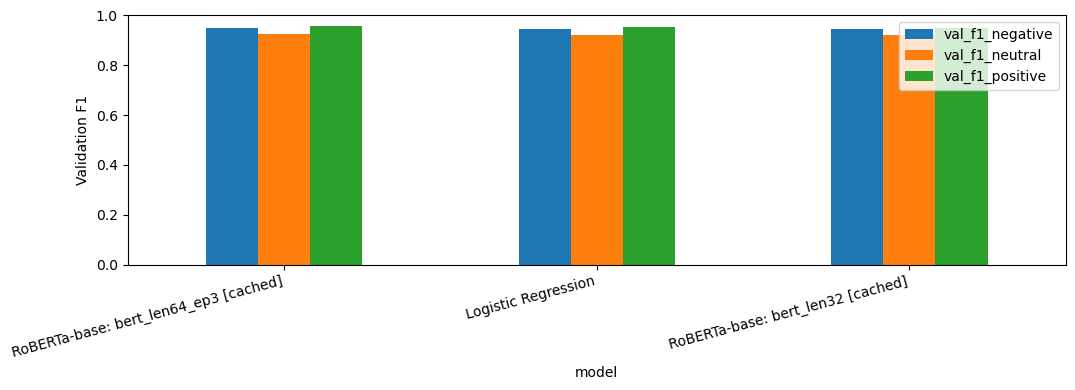

In [17]:
compare = baseline_results[[c for c in baseline_results.columns if c.startswith('val_')]].copy()
use_experiment('montra-sentiment')
for run in bert_runs:
    name = f"{BERT_LABEL}: {run['run']}" + (' [cached]' if BERT_FROM_CACHE else '')
    compare.loc[name] = [run[column] for column in compare.columns]
    with mlflow.start_run(run_name=run['run']):
        mlflow.set_tags({'stage': 'bert', 'model_family': 'transformer', 'source': 'verified cache' if BERT_FROM_CACHE else 'new training'})
        mlflow.log_params({'model': BERT_LABEL, 'epochs': run['epochs'], 'train_rows': run['train_rows'], 'max_len': run['max_len']})
        mlflow.log_metrics({key: value for key, value in run.items() if key.startswith('val_') and isinstance(value, (int, float))})
    print(name, '| training rows:', run['train_rows'], '| epochs:', run['epochs'])
    display(pd.DataFrame(run['epoch_history']))
compare = compare.sort_values('val_f1_macro', ascending=False)
display(compare.round(4))
compare[['val_f1_negative', 'val_f1_neutral', 'val_f1_positive']].plot.bar(figsize=(11, 4))
plt.ylim(0, 1); plt.ylabel('Validation F1'); plt.xticks(rotation=15, ha='right'); plt.tight_layout(); plt.show()


## 13. Save outputs for machine learning and analytics

The next notebook loads this handoff in a new kernel. It contains the review splits, sentence aspects/sentiment, fitted Logistic Regression baseline, topic word lookup and available RoBERTa results. 

In [18]:
sentences.to_csv(PROC_DIR / 'review_sentences_topics.csv', index=False)
state_names = ['reviews_clean', 'nlp_corpus', 'sentences', 'ASPECTS', 'ASPECT_LEXICON', 'ASPECT_GROUP',
    'train_df', 'val_df', 'test_df', 'corpus', 'baseline_results', 'baseline_pipes', 'bert_runs', 'BERT_FROM_CACHE',
    'BERT_MODEL_NAME', 'BERT_LABEL', 'BERT_TRAIN_LIMIT', 'LABEL2ID', 'data_signature', 'split_ids']
state = {name: globals()[name] for name in state_names}
state['topic_lookup'] = {int(t): topic_model.get_topic(int(t)) for t in topic_model.get_topics()}
joblib.dump(state, MODEL_DIR / 'phase7_handoff.joblib', compress=3)
joblib.dump(baseline, MODEL_DIR / 'logistic_baseline.joblib', compress=3)
topic_table.to_csv(REPORT_DIR / 'simplified_topics.csv', index=False)
compare.to_csv(REPORT_DIR / 'phase7_model_comparison.csv')
aspect_sent.to_csv(REPORT_DIR / 'simplified_aspect_sentiment.csv')
print('Saved the Phase 7 handoff. Next: run the updated machine_learning_and_analytics.ipynb.')


Saved the Phase 7 handoff. Next: run the updated machine_learning_and_analytics.ipynb.
